# 04 · Aplicar el modelo final al test

Este es el **único** notebook que mira las campañas de test (**2020/21 a 2024/25**). Reglas:

- Se **carga** el modelo guardado en `03_entrenar_final.ipynb`: **no se reentrena ni se cambia nada** después de ver estos resultados.
- Los baselines también se ajustan **solo con el train** (≤ 2019/20), igual que el modelo.
- El test incluye la **sequía 2022/23**, una de las peores de la historia: es la prueba de fuego.

> Sobre los rezagos: para predecir, por ejemplo, la campaña 2023/24 el modelo usa el rendimiento real de 2022/23. Es legítimo: al 10/02/2024 esa cosecha ya terminó y se conoce. El modelo **no** se reentrena con esos años.

In [1]:
import json, warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from comun import *

estilo_graficos()
pd.set_option("display.width", 200)

modelo = joblib.load(RAIZ / "models" / "modelo_final.joblib")
ficha = json.loads((RAIZ / "models" / "modelo_final.json").read_text(encoding="utf-8"))
assert ficha["campanias_train"][1] == ULTIMO_TRAIN, "el modelo tiene que estar entrenado solo hasta 2019/20"
print("Modelo:", ficha["modelo"], "· entrenado con campañas", ficha["campanias_train"])

d = cargar()
train = d[d.anio <= ULTIMO_TRAIN]
test = d[d.anio.isin(TEST)].copy()
print(f"Test: {len(test):,} filas · {test.departamento_id.nunique()} departamentos")
test.groupby("anio").size().rename("departamentos por campaña").to_frame().T

Modelo: Promedio simple ElasticNet + CatBoost (target relativo) · entrenado con campañas [1999, 2019]


Test: 1,250 filas · 253 departamentos


anio,2020,2021,2022,2023,2024
departamentos por campaña,249,251,251,249,250


In [2]:
# Baselines ajustados SOLO con el train
baselines = {"Baseline: media del depto": ModeloRendimiento(None, "media_dep").fit(train),
             "Baseline: depto + tendencia": ModeloRendimiento(None, "tendencia").fit(train)}

en, cat = modelo.modelos_
P = pd.DataFrame({"anio": test.anio.to_numpy(), "provincia": test.provincia.to_numpy(),
                  "departamento": test.departamento.to_numpy(), "departamento_id": test.departamento_id.to_numpy(),
                  "real": test[TARGET].to_numpy(),
                  "Modelo final": modelo.predict(test),           # ← la predicción que se entrega
                  "ElasticNet (componente)": en.predict(test),     # sus dos mitades, solo para entenderlo
                  "CatBoost (componente)": cat.predict(test)})
for nombre, b in baselines.items():
    P[nombre] = b.predict(test)
assert np.allclose(P["Modelo final"], (P["ElasticNet (componente)"] + P["CatBoost (componente)"]) / 2)

## Resultado general en test

In [3]:
SEQUIA = 2022     # campaña 2022/23
MODELOS = ["Modelo final", "ElasticNet (componente)", "CatBoost (componente)",
           "Baseline: media del depto", "Baseline: depto + tendencia"]

def metricas(g, m):
    e = g[m] - g.real
    return {"RMSE": rmse(g.real, g[m]), "MAE": e.abs().mean(), "sesgo": e.mean()}

filas = []
for m in MODELOS:
    r = {"modelo": m, **metricas(P, m)}
    s = P[P.anio == SEQUIA]
    r.update({"RMSE sequía 22/23": rmse(s.real, s[m]), "sesgo sequía 22/23": (s[m] - s.real).mean()})
    filas.append(r)
res = pd.DataFrame(filas).set_index("modelo")
BASE_TEST = res.loc["Baseline: media del depto", "RMSE"]
res["mejora vs media depto %"] = 100 * (1 - res.RMSE / BASE_TEST)
res.round(1)

,RMSE,MAE,sesgo,RMSE sequía 22/23,sesgo sequía 22/23,mejora vs media depto %
modelo,,,,,,
Modelo final,541.4,428.3,29.1,637.0,372.0,18.6
ElasticNet (componente),542.3,435.7,68.5,669.1,433.0,18.5
CatBoost (componente),559.0,436.3,-10.4,624.9,311.1,15.9
Baseline: media del depto,665.1,512.7,30.0,1011.7,731.2,0.0
Baseline: depto + tendencia,792.4,604.8,426.3,1329.0,1127.5,-19.1


In [4]:
val = ficha["validacion_expansiva_2010_2019"]
f = res.loc["Modelo final"]
pd.DataFrame({"Validación 2010–2019": [val["rmse"], val["mae"], val["sesgo"], val["mejora_vs_media_depto_pct"]],
              "Test 2020–2024": [f.RMSE, f.MAE, f.sesgo, f["mejora vs media depto %"]]},
             index=["RMSE", "MAE", "sesgo", "mejora vs media depto %"]).round(1)

,Validación 2010–2019,Test 2020–2024
RMSE,510.6,541.4
MAE,408.8,428.3
sesgo,-50.9,29.1
mejora vs media depto %,21.5,18.6


## Campaña por campaña

In [5]:
por_anio = pd.concat({m: P.groupby("anio").apply(lambda g: pd.Series(metricas(g, m)), include_groups=False)
                      for m in ["Modelo final", "Baseline: media del depto", "Baseline: depto + tendencia"]}, axis=1)
por_anio.index = [f"{a}/{(a + 1) % 100:02d}" for a in por_anio.index]
por_anio["rinde real promedio"] = P.groupby("anio").real.mean().to_numpy()
por_anio.round(0)

Modelo final               Baseline: media del depto               Baseline: depto + tendencia                 rinde real promedio
                RMSE    MAE  sesgo                      RMSE    MAE  sesgo                        RMSE     MAE   sesgo                    
2020/21        426.0  341.0  -29.0                     511.0  399.0 -182.0                       514.0   419.0   150.0              2620.0
2021/22        492.0  378.0   20.0                     492.0  391.0  -19.0                       594.0   494.0   345.0              2451.0
2022/23        637.0  563.0  372.0                    1012.0  867.0  731.0                      1329.0  1157.0  1127.0              1701.0
2023/24        538.0  409.0  -47.0                     611.0  472.0 -264.0                       580.0   441.0   164.0              2703.0
2024/25        588.0  450.0 -173.0                     556.0  432.0 -121.0                       644.0   509.0   340.0              2550.0

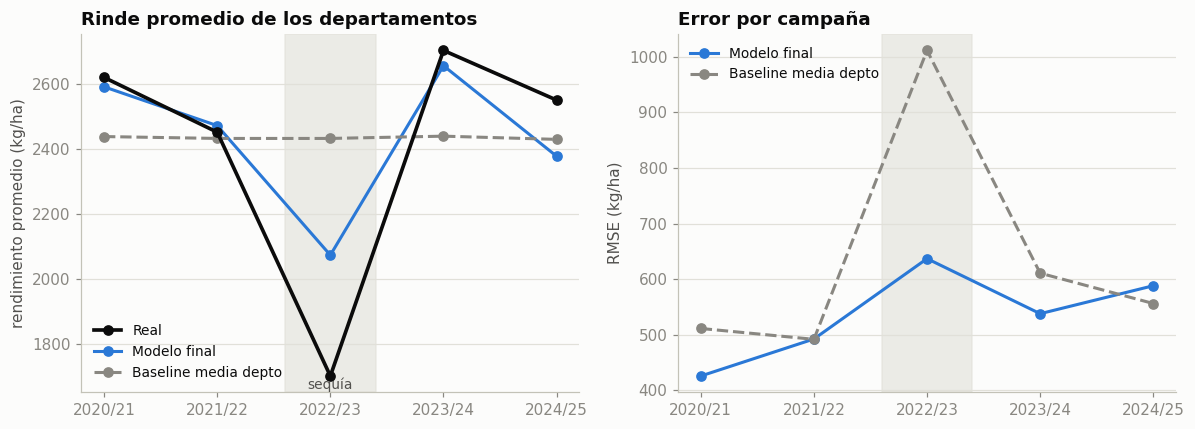

In [6]:
campanias = [f"{a}/{(a + 1) % 100:02d}" for a in TEST]
fig, axs = plt.subplots(1, 2, figsize=(11, 4))

ax = axs[0]
media = P.groupby("anio")[["real", "Modelo final", "Baseline: media del depto"]].mean()
ax.plot(campanias, media.real, "-o", color=COLORES["Real"], label="Real", lw=2.4, zorder=3)
ax.plot(campanias, media["Modelo final"], "-o", color=COLORES["Modelo final"], label="Modelo final")
ax.plot(campanias, media["Baseline: media del depto"], "--o", color=COLORES["Baseline"], label="Baseline media depto")
ax.set_ylabel("rendimiento promedio (kg/ha)")
ax.set_title("Rinde promedio de los departamentos")
ax.legend(loc="lower left", fontsize=9)

ax = axs[1]
ax.plot(campanias, por_anio[("Modelo final", "RMSE")], "-o", color=COLORES["Modelo final"], label="Modelo final")
ax.plot(campanias, por_anio[("Baseline: media del depto", "RMSE")], "--o", color=COLORES["Baseline"],
        label="Baseline media depto")
ax.set_ylabel("RMSE (kg/ha)")
ax.set_title("Error por campaña")
ax.legend(loc="upper left", fontsize=9)
for a in axs:
    i = TEST.index(SEQUIA)
    a.axvspan(i - .4, i + .4, color="#e1e0d9", alpha=.6, zorder=0)
axs[0].text(TEST.index(SEQUIA), axs[0].get_ylim()[0], "sequía", ha="center", va="bottom", fontsize=9, color="#52514e")
plt.tight_layout(); plt.show()

## La sequía 2022/23 en detalle

Modelo final                 sobreestima en   74% de los departamentos · sesgo medio  +372 kg/ha · rinde promedio predicho / real = 1.22
Baseline: media del depto    sobreestima en   80% de los departamentos · sesgo medio  +731 kg/ha · rinde promedio predicho / real = 1.43

Respecto del rinde normal (2432 kg/ha), la caída real fue de 731 kg/ha; el modelo anticipó 359 kg/ha → capturó el 49% de la caída.


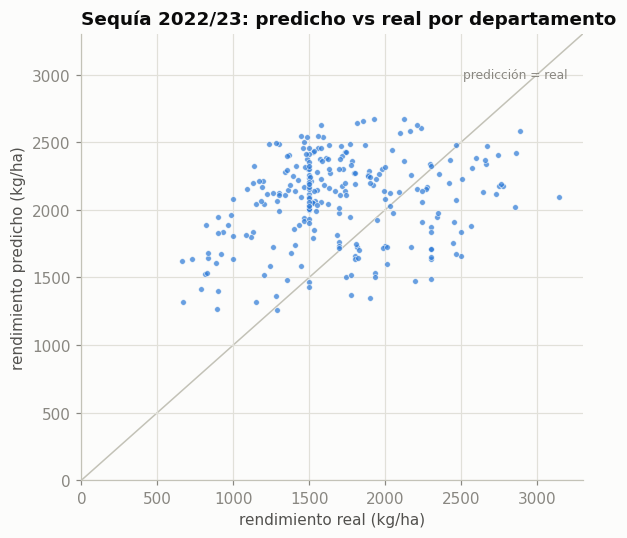

In [7]:
s = P[P.anio == SEQUIA]
for m in ["Modelo final", "Baseline: media del depto"]:
    sobre = (s[m] > s.real).mean() * 100
    print(f"{m:28s} sobreestima en {sobre:4.0f}% de los departamentos · "
          f"sesgo medio {(s[m] - s.real).mean():+5.0f} kg/ha · "
          f"rinde promedio predicho / real = {s[m].mean() / s.real.mean():.2f}")
normal = s["Baseline: media del depto"].mean()
caida_real, caida_pred = normal - s.real.mean(), normal - s["Modelo final"].mean()
print(f"\nRespecto del rinde normal ({normal:.0f} kg/ha), la caída real fue de {caida_real:.0f} kg/ha; "
      f"el modelo anticipó {caida_pred:.0f} kg/ha → capturó el {100 * caida_pred / caida_real:.0f}% de la caída.")

fig, ax = plt.subplots(figsize=(5.5, 5))
lim = [0, max(s.real.max(), s["Modelo final"].max()) * 1.05]
ax.plot(lim, lim, color="#c3c2b7", lw=1, zorder=1)
ax.scatter(s.real, s["Modelo final"], s=14, color=COLORES["Modelo final"], alpha=.7, edgecolor="#fcfcfb", lw=.5, zorder=2)
ax.text(lim[1] * .97, lim[1] * .9, "predicción = real", ha="right", fontsize=8, color="#898781")
ax.set_xlim(lim); ax.set_ylim(lim); ax.grid(axis="x", visible=True)
ax.set_xlabel("rendimiento real (kg/ha)"); ax.set_ylabel("rendimiento predicho (kg/ha)")
ax.set_title("Sequía 2022/23: predicho vs real por departamento")
plt.tight_layout(); plt.show()

### ¿Por qué se quedó corto? Lo que pasó después del 10/02

El modelo solo ve el clima hasta el 10 de febrero. La tabla muestra las anomalías (en desvíos estándar respecto de lo normal del departamento) **antes** (floración) y **después** (llenado de granos, febrero–marzo) de esa fecha. Esto es solo descriptivo: las columnas de llenado **no** entran al modelo.

In [8]:
cols = {"anom_floracion_balance_mm": "balance hídrico floración", "anom_floracion_dias_calor": "días de calor floración",
        "anom_llenado_balance_mm": "balance hídrico llenado (después del 10/02)",
        "anom_llenado_dias_calor": "días de calor llenado (después del 10/02)"}
clima = d[d.anio.isin([2017] + TEST)].groupby("anio")[list(cols)].mean().rename(columns=cols)
clima.index = [f"{a}/{(a + 1) % 100:02d}" for a in clima.index]
clima.T.round(2)

,2017/18,2020/21,2021/22,2022/23,2023/24,2024/25
balance hídrico floración,-0.47,-0.09,0.49,-0.60,-0.66,-0.50
días de calor floración,0.68,-0.40,-0.47,1.56,1.31,1.71
balance hídrico llenado (después del 10/02),-1.19,-0.41,0.37,-1.14,0.55,0.32
días de calor llenado (después del 10/02),0.82,0.81,-0.13,2.88,0.78,0.95


In [9]:
prov = (P.assign(err=P["Modelo final"] - P.real)
        .groupby("provincia").agg(departamentos=("departamento_id", "nunique"),
                                  RMSE=("err", lambda e: np.sqrt(np.mean(e ** 2))), sesgo=("err", "mean"))
        .sort_values("departamentos", ascending=False))
prov.round(0)

,departamentos,RMSE,sesgo
provincia,,,
Buenos Aires,88,435.0,120.0
Córdoba,22,538.0,-2.0
Santiago del Estero,22,680.0,-303.0
Chaco,19,717.0,172.0
Santa Fe,19,646.0,-74.0
Entre Ríos,16,530.0,93.0
Salta,14,437.0,170.0
La Pampa,13,337.0,24.0
Tucumán,13,420.0,67.0


In [10]:
salida = RAIZ / "resultados"
salida.mkdir(exist_ok=True)
P.to_csv(salida / "predicciones_test.csv", index=False)
res.round(2).to_csv(salida / "metricas_test.csv")
print("Guardado: resultados/predicciones_test.csv y resultados/metricas_test.csv")

Guardado: resultados/predicciones_test.csv y resultados/metricas_test.csv


## Conclusiones

**1. El modelo generaliza: el test confirma lo que dijo la validación.**
RMSE en test **541 kg/ha** contra **665** del baseline (promedio histórico del departamento): **18,6 % mejor**. En validación había dado 511 y 21,5 %. Que el test dé un poco peor es lo esperable: los hiperparámetros se eligieron mirando la validación (Optuna) y el test tiene una sequía extrema. No hay señales de sobreajuste.

**2. En la sequía 2022/23 es donde más aporta, pero se queda corto.**
- Error: **637 kg/ha contra 1.012** del baseline (**−37 %**).
- El modelo *vio venir* la sequía: anticipó cerca de **la mitad de la caída** del rinde respecto de lo normal.
- Pero **sobreestimó** el rinde en ~3 de cada 4 departamentos (sesgo **+372 kg/ha**). Es el mismo patrón que en la validación (sequía 2017/18).
- Explicación: el modelo predice al 10/02 y la sequía **se agravó después**: el llenado de granos tuvo la peor anomalía de calor del período (+2,9 desvíos) y balance hídrico muy negativo. Eso el modelo no lo puede ver **por diseño**.

**3. No gana todos los años.** En 2021/22 empata con el baseline y en 2024/25 es algo peor (588 contra 556), con sesgo negativo (predijo de menos). El valor está en los años extremos, que son justamente los que le importan a la aseguradora.

**4. Comparación con el modelo del Examen 1** (HGB sobre el rinde crudo; números del notebook 01): en test general **541 contra 584** (mejor). En la sequía 2022/23, en cambio, **637 contra 585** (peor). El modelo nuevo es mejor en promedio y en la validación, pero no en ese año puntual.

**5. Para el negocio.**
- Sirve como **herramienta de reservas** al 10/02: reduce el error ~19 % en general y ~37 % en sequía.
- Como **sobreestima sistemáticamente en sequía**, cuando el clima a febrero ya marca un año seco conviene **sumar un margen prudencial** a la reserva y **actualizar la estimación en marzo**, con el llenado ya observado.

**Limitaciones a declarar:** 10 años de validación y 5 de test (pocas sequías para medir); clima del centroide del departamento, no del lote; los hiperparámetros con Optuna son algo optimistas en validación; la normal climática (≤ 2018) incluye años de validación (solo afecta a las features, no al target).